# Day 3 Reference: Agents, Tools, Memory, and MCP

This notebook is a guided reference for building LangChain agents and connecting them to tools. It progresses from a simple conversational agent to tool use, graph visualization, conversation memory, structured responses, middleware, and browser tools through the Model Context Protocol (MCP).

## Before you begin

- Configure model credentials in your environment (for example, in a `.env` file) before invoking model-backed cells.
- The city weather and population tools use **example data**, not live services.
- The browser examples require Node.js/npm and Chrome; the MCP example starts a local Playwright MCP server through `npx`.
- Run cells from top to bottom so each example has the imports and tools it needs.

In [1]:
# Load environment settings and the libraries used throughout the examples.
from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field

from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.tools import tool
from langchain_mcp_adapters.client import MultiServerMCPClient

from langgraph.checkpoint.memory import MemorySaver

# Read API credentials from .env into the process environment, if present.
load_dotenv()

True

## 1. Basic agents and tool use

The first example sends a message to an agent without tools. The next defines two sample city tools and lets an agent call them; the final cell in this section visualizes the agent graph.

In [2]:
# Create an agent with a concise behavior instruction and no external tools.
agent = create_agent(
    model='openai:gpt-5.4-mini',
    system_prompt = 'You are a helpful assistant who answers concisely',
)

# The invoke input is a conversation state containing a list of messages.
result = agent.invoke(
    {
        'messages': [
            {
                'role': 'user',
                'content': 'What is the Model Context Protocol, in two sentences?'
            }
        ]
    }
)

# The final message is the assistant's response to the prompt.
print(result['messages'][-1].content)


The Model Context Protocol (MCP) is an open standard for connecting AI models and assistants to external data sources, tools, and services in a consistent way. It lets apps expose capabilities through a common interface, so models can access context and act on systems without custom integrations for each one.


In [3]:
# These tools expose local sample data; they are not live APIs.
@tool
def get_weather(city: str) -> str:
    """ Return today's weather for a city. """
    pretend = {
        'London': 'rainy, 14 degrees',
        'Rome': 'sunny, 27 degrees'
    }
    # Do not invent a weather value for cities outside this sample dataset.
    return pretend.get(city, 'unknown')

@tool
def get_population(city: str) -> str:
    """ Return the population of a city. """
    pretend = {
        'London': '8.9 million',
        'Rome': '2.8 million'
    }
    return pretend.get(city, 'unknown')

# Giving the agent these tools lets it look up both requested facts.
agent = create_agent(
    model='openai:gpt-5.4-mini',
    tools=[get_weather, get_population],
    system_prompt='You are a travel assistant. Use your tools to answer questions about cities.',
)

# Ask a question that requires both tools, then display the assistant reply.
result = agent.invoke(
    {
        'messages': [
            {
                'role': 'user',
                'content': 'What is the weather and population of Rome?'
            }
        ]
    }
)
print(result['messages'][-1].content)

Rome is currently **sunny, 27 degrees**, and its population is **2.8 million**.


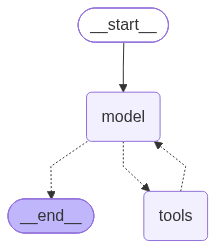

In [4]:
# Render the agent's graph so its structure can be inspected visually.
display(Image(agent.get_graph().draw_mermaid_png()))

### Summary: Basic agents and tools

`create_agent` combines a model, instructions, and optional tools. Tool-backed agents can retrieve example data, and their graph can be rendered for inspection.

## 2. Conversation memory and structured output

The next examples keep state between turns with an in-memory checkpointer, then constrain a response to a Pydantic model. The memory lasts only for the current kernel process and is keyed by the configured thread ID.

In [5]:
# A checkpointer stores conversation state separately for each thread_id.
memory_agent = create_agent(
    model='openai:gpt-5.4-mini',
    tools=[get_weather],
    checkpointer=MemorySaver(),
    system_prompt='You are a travel assistant. Use your tools to answer questions about cities.',
)

# Reuse this thread ID on both calls to continue the same conversation.
config = {'configurable': {'thread_id': 'trip-planning'}}
# The first turn establishes London as the destination in this thread.
memory_agent.invoke(
    {
        'messages': [
            {
                'role': 'user',
                'content': 'I am planning a trip to London'
            }
        ]
    }, config)
# The second turn checks whether the agent can use the saved context.
result = memory_agent.invoke(
    {
        'messages': [
            {
                'role': 'user',
                'content': 'What is the weather like where I am going on my trip?'
            }
        ]
    }, config)
print(result['messages'][-1].content)

London is currently **rainy and 14°C**.  

You may want to pack a **rain jacket, umbrella, and layers**.


In [6]:
# This Pydantic model defines the fields required in a structured report.
class CityReport(BaseModel):
    city: str = Field(description='The city name')
    weather: str = Field(description='A short weather description')
    population: str = Field(description='The population')

# response_format asks the agent to return data matching CityReport.
report_agent = create_agent(
    model='openai:gpt-5.4-mini',
    tools=[get_weather, 
           get_population],
    response_format=CityReport,
)

result = report_agent.invoke(
    {
        'messages': [
            {
                'role': 'user',
                'content': 'Give me a report on London'
            }
        ]
    }
)
# Read the validated model from structured_response, not message text.
report = result['structured_response']
print(report)
print("Just the weather:", report.weather)

city='London' weather='rainy, 14 degrees' population='8.9 million'
Just the weather: rainy, 14 degrees


### Summary: Memory and structured responses

A shared thread ID lets the checkpointer resume prior conversation context. A Pydantic response model makes the expected fields explicit and accessible as typed attributes.

## 3. Middleware for observing tool calls

The wrapper middleware logs each tool name and arguments, then delegates execution to the original handler so the tools still run normally.

In [7]:
# Middleware observes a tool call, then forwards it to the normal handler.
@wrap_tool_call
def log_tool_calls(request, handler):
    call = request.tool_call
    print(f"[middleware] calling {call['name']} with {call['args']}")
    return handler(request)

watched_agent = create_agent(
    model='openai:gpt-5.4-mini',
    tools=[get_weather,
           get_population],
    system_prompt='You are a travel assistant. Use your tools to answer city questions.',
    middleware=[log_tool_calls],
)

# The middleware prints each lookup while the agent answers the request.
result = watched_agent.invoke(
    {
        'messages':[
            {
                'role': 'user',
                'content': 'Weather and population of London and Rome?'
            }
        ]
    }
)
print("\nFinal answer:",result['messages'][-1].content)

[middleware] calling get_weather with {'city': 'London'}
[middleware] calling get_population with {'city': 'London'}
[middleware] calling get_weather with {'city': 'Rome'}
[middleware] calling get_population with {'city': 'Rome'}

Final answer: Here you go:

- London: rainy, 14 degrees; population 8.9 million
- Rome: sunny, 27 degrees; population 2.8 million


### Summary: Middleware

The middleware is a transparent observation point: it reports tool calls and forwards them without changing their results.

## 4. Browser prerequisites and screenshot

Check that Node.js and npm are available, then run Playwright with Chrome. The screenshot command now uses `subprocess.run(check=True)`, so a failed browser command is reported at its source rather than followed by a misleading missing-file error.

In [8]:
# Check the Node.js and npm runtimes needed by the browser examples.
!node --version
!npm --version

v26.11.1
11.20.0


## 5. Load browser tools through MCP

The client starts the Playwright MCP server as a local subprocess using standard input/output (stdio), requests its tool definitions, and prints the available tool names. This cell loads the tools; it does not yet attach them to an agent.

⠙⠹⠸Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png
⠙

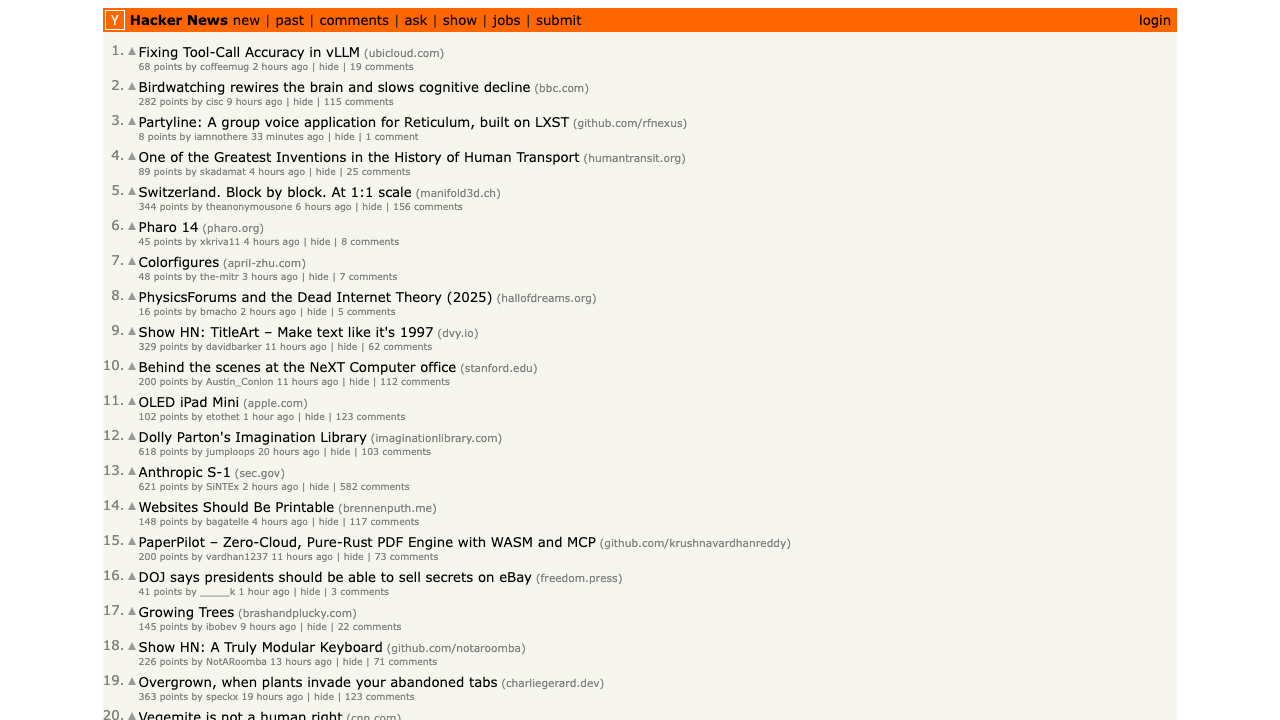

In [11]:
import subprocess
from pathlib import Path
from IPython.display import Image, display

# check=True stops on a failed command instead of producing a later
# FileNotFoundError when the screenshot was never written.
screenshot_path = Path('playwright_check.png')
subprocess.run(
    [
        'npx', '-y', 'playwright@latest', 'screenshot', '--channel=chrome',
        'https://news.ycombinator.com', str(screenshot_path),
    ],
    check=True,
)
display(Image(filename=str(screenshot_path)))

In [12]:
# Apply a Windows-only stderr adjustment for the MCP stdio transport.
import sys

if sys.platform == 'win32':
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, 
                                        errlog=subprocess.DEVNULL)
    print("applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Not Windows, so nothing to do here


In [13]:
# Configure a local Playwright MCP server launched by npx over stdio.
client = MultiServerMCPClient({
    'playwright': {
        'transport': 'stdio',
        'command': 'npx',
        'args': ['-y', '@playwright/mcp@latest', 
                 '--isolated'],
    }
})
# Fetch the server's tool definitions, then list them for inspection.
browser_tools = await client.get_tools()
print(f"Loaded {len(browser_tools)} browser tools:")
for t in browser_tools:
    print(" -", t.name)

Loaded 25 browser tools:
 - browser_close
 - browser_resize
 - browser_console_messages
 - browser_handle_dialog
 - browser_emulate_media
 - browser_evaluate
 - browser_file_upload
 - browser_drop
 - browser_find
 - browser_fill_form
 - browser_press_key
 - browser_type
 - browser_navigate
 - browser_navigate_back
 - browser_network_requests
 - browser_network_request
 - browser_run_code_unsafe
 - browser_take_screenshot
 - browser_snapshot
 - browser_click
 - browser_drag
 - browser_hover
 - browser_select_option
 - browser_tabs
 - browser_wait_for


## Conclusion

You have seen how to create a basic agent, expose tools, preserve conversation state, request structured data, inspect tool calls with middleware, and discover browser tools through MCP. The examples use sample city data, an in-memory checkpointer, and the current `latest` Playwright packages, so pin package versions when reproducible environments are important.

For further practice, add a real data source behind a tool and pass `browser_tools` to an agent when you are ready to let it use the browser.